# Анализ данных в задачах ИБ. Лабораторная работа 1
## Работу выполнил: Паньшин Кирилл Ильич РИ-431001

Тема проекта: детектор спама для почты организации.

Датасет Spambase из репозитория UCI: https://archive.ics.uci.edu/dataset/94/spambase

## 1. Бизнес-постановка задачи

В компанию каждый день приходит много спама. Он отвлекает сотрудников, а через такие письма часто приходит фишинг и вредоносные вложения. Почтовый шлюз должен сам отправлять спам в карантин, а нормальные письма доставлять во входящие.

Результат нужен отделу ИБ и администраторам почты, которые настраивают фильтр, и обычным сотрудникам, которые получают почту.

Для каждого письма нужно получить оценку, насколько оно похоже на спам. Если оценка выше порога, письмо уходит в карантин. Пользователь может зайти в карантин и достать письмо обратно.

Ожидаем, что спама во входящих станет меньше и сотрудники будут тратить на него меньше времени. Это пока предположение, а не проверенный результат.

Главный риск в том, что фильтр уберет в спам рабочее письмо. Человек его не увидит, и это хуже, чем один пропущенный спам. Авторы датасета тоже пишут, что ложные срабатывания очень нежелательны.

Ограничения: данные собраны в 1999 году в одной компании (Hewlett-Packard).

## 2. Постановка ML-задачи

Тип задачи: бинарная классификация (обучение с учителем).

Одна строка в данных это одно письмо.

Целевая переменная spam: 1 это спам (положительный класс), 0 это обычное письмо (отрицательный класс).

Признаки: 57 числовых признаков, посчитанных по тексту письма:
* 48 признаков word_freq_*: какой процент слов в письме совпадает с определенным словом;
* 6 признаков char_freq_*: какой процент символов совпадает с определенным символом;
* 3 признака capital_run_length_*: средняя, максимальная и общая длина серий заглавных букв.

Модель должна выдавать вероятность того, что письмо спам. Дальше по порогу получаем метку 0 или 1.

Качество будем проверять на отложенной выборке или кросс-валидации по метрике из раздела 3.

Почему классификация: шлюзу нужно принять одно из двух решений, доставить письмо или убрать в карантин.

Проверка на утечку целевой переменной: все признаки считаются только по тексту письма, они есть сразу, когда письмо пришло. Признаков вроде "пользователь пожаловался на письмо" нет, так что утечки нет. Есть проблема: слова george, hp, hpl, 650 относятся к конкретному человеку и компании, у которых собирали обычные письма. Модель может научиться на них, а в другой компании они работать не будут. Это проверим в EDA.

## 3. Выбор метрики

Основная метрика: F0.5 (F-beta с beta = 0.5).

Ошибка FP (рабочее письмо попало в спам) для нас дороже, чем FN (спам попал во входящие). Пропущенный спам человек увидит и удалит, а пропавшее рабочее письмо может вообще никто не заметить. Поэтому нам важнее Precision: какая доля писем в карантине действительно спам.

Но только Precision смотреть нельзя. Если фильтр будет блокировать пару самых очевидных писем, Precision будет высокий, а спам почти весь пройдет, то есть упадет Recall. F0.5 учитывает обе метрики, но Precision в ней весит больше. Если фильтр ничего не ловит, F0.5 будет 0.

Чем выше порог, тем меньше FP, но больше пропущенного спама. Порог потом будем подбирать по кривой Precision-Recall.

Дополнительно будем смотреть Precision и Recall по отдельности, PR-AUC (качество без привязки к порогу) и матрицу ошибок.

Accuracy не подходит, потому что считает обе ошибки одинаковыми. К тому же модель, которая все письма называет нормальными, уже получает accuracy около 0.61, это проверим ниже.

Обоснование: берем F0.5, потому что заблокированное рабочее письмо обходится дороже пропущенного спама, а F0.5 дает больший вес Precision и при этом не дает получить хорошую оценку фильтру, который почти ничего не ловит.

## 4. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.cbook import boxplot_stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, fbeta_score

sns.set_theme()
pd.set_option('display.max_columns', 60)

## 5. Загрузка данных

Грузим через пакет ucimlrepo. Если UCI не открывается, берем копию того же файла с GitHub (репозиторий PMLB).

Названия колонок задаем сами в том порядке, как в описании датасета (файл spambase.names), чтобы они всегда были одинаковые.

In [2]:
words = ['make', 'address', 'all', '3d', 'our', 'over', 'remove', 'internet', 'order', 'mail',
         'receive', 'will', 'people', 'report', 'addresses', 'free', 'business', 'email', 'you',
         'credit', 'your', 'font', '000', 'money', 'hp', 'hpl', 'george', '650', 'lab', 'labs',
         'telnet', '857', 'data', '415', '85', 'technology', '1999', 'parts', 'pm', 'direct', 'cs',
         'meeting', 'original', 'project', 're', 'edu', 'table', 'conference']
chars = [';', '(', '[', '!', '$', '#']

word_cols = ['word_freq_' + w for w in words]
char_cols = ['char_freq_' + c for c in chars]
cap_cols = ['capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total']
features = word_cols + char_cols + cap_cols

try:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=94)
    data = ds.data.features.copy()
    data.columns = features
    data['spam'] = ds.data.targets.iloc[:, 0].values
    print('Загружено с UCI')
except Exception:
    url = 'https://media.githubusercontent.com/media/EpistasisLab/pmlb/master/datasets/spambase/spambase.tsv.gz'
    data = pd.read_csv(url, sep='\t')
    data.columns = features + ['spam']
    print('UCI недоступен, загружено с GitHub (PMLB)')

UCI недоступен, загружено с GitHub (PMLB)


Сверим данные с описанием датасета. Там указано 4601 письмо, 1813 из них спам, среднее capital_run_length_total = 283.2893, максимум 15841.

In [3]:
print('Писем:', len(data))
print('Спама:', data['spam'].sum())
print('Среднее capital_run_length_total:', round(data['capital_run_length_total'].mean(), 4))
print('Максимум capital_run_length_total:', data['capital_run_length_total'].max())

Писем: 4601
Спама: 1813
Среднее capital_run_length_total: 283.2893
Максимум capital_run_length_total: 15841


Все совпадает с описанием, значит данные загружены правильно и колонки стоят на своих местах.

## 6. Первичный осмотр данных

In [4]:
data.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,0.00,0.64,0.00,0.00,0.00,0.32,0.00,1.29,1.93,0.00,0.96,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,0.21,0.79,0.65,0.21,0.14,0.14,0.07,0.28,3.47,0.00,1.59,0.0,0.43,0.43,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.07,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,0.38,0.45,0.12,0.00,1.75,0.06,0.06,1.03,1.36,0.32,0.51,0.0,1.16,0.06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.06,0.0,0.0,0.12,0.0,0.06,0.06,0.0,0.0,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,0.31,0.31,0.31,0.00,0.00,0.31,0.00,0.00,3.18,0.00,0.31,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [5]:
data.tail()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,word_freq_receive,word_freq_will,word_freq_people,word_freq_report,word_freq_addresses,word_freq_free,word_freq_business,word_freq_email,word_freq_you,word_freq_credit,word_freq_your,word_freq_font,word_freq_000,word_freq_money,word_freq_hp,word_freq_hpl,word_freq_george,word_freq_650,word_freq_lab,word_freq_labs,word_freq_telnet,word_freq_857,word_freq_data,word_freq_415,word_freq_85,word_freq_technology,word_freq_1999,word_freq_parts,word_freq_pm,word_freq_direct,word_freq_cs,word_freq_meeting,word_freq_original,word_freq_project,word_freq_re,word_freq_edu,word_freq_table,word_freq_conference,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
4596,0.31,0.0,0.62,0.0,0.00,0.31,0.0,0.0,0.0,0.0,0.0,1.88,0.00,0.0,0.0,0.0,0.0,0.0,0.62,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.31,0.31,0.31,0.0,0.0,0.000,0.232,0.0,0.000,0.0,0.0,1.142,3,88,0
4597,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,6.00,0.0,2.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,2.00,0.0,0.0,0.000,0.000,0.0,0.353,0.0,0.0,1.555,4,14,0
4598,0.30,0.0,0.30,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,1.80,0.30,0.0,0.0,0.0,0.0,0.9,1.50,0.0,0.30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,1.20,0.0,0.0,0.102,0.718,0.0,0.000,0.0,0.0,1.404,6,118,0
4599,0.96,0.0,0.00,0.0,0.32,0.00,0.0,0.0,0.0,0.0,0.0,0.32,0.00,0.0,0.0,0.0,0.0,0.0,1.93,0.0,0.32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.32,0.00,0.32,0.0,0.0,0.000,0.057,0.0,0.000,0.0,0.0,1.147,5,78,0
4600,0.00,0.0,0.65,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.65,0.0,0.0,0.0,0.0,0.0,4.60,0.0,0.65,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,1.97,0.65,0.0,0.0,0.000,0.000,0.0,0.125,0.0,0.0,1.250,5,40,0


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_report            4601 non-null   

Размер датасета: 4601 строка и 58 столбцов (57 признаков и целевая переменная spam).

Все признаки числовые: 55 типа float и 3 типа int. Категориальных признаков нет, кодировать ничего не нужно.

Самих текстов писем в датасете нет, только уже посчитанные признаки. Поэтому новые признаки из текста добавить не получится.

## 7. Пропуски и дубликаты

In [7]:
print('Всего пропусков:', data.isna().sum().sum())

dup = data.duplicated()
print('Полных дубликатов:', dup.sum())
print('Из них спам / не спам:', data.loc[dup, 'spam'].sum(), '/', (data.loc[dup, 'spam'] == 0).sum())

# одинаковые письма, у которых разная метка
conflicts = data.groupby(features)['spam'].nunique()
print('Одинаковых писем с разной меткой:', (conflicts > 1).sum())

Всего пропусков: 0
Полных дубликатов: 391
Из них спам / не спам: 134 / 257
Одинаковых писем с разной меткой: 3


Вывод: пропусков нет (на сайте UCI написано, что пропуски есть, но в самих данных их нет). Есть 391 полный дубликат, это примерно 8.5% данных. Скорее всего это пересылки и одинаковые рассылки. Еще есть 3 группы одинаковых писем с разной меткой, это просто ошибки разметки.

Если дубликаты попадут и в обучающую, и в тестовую выборку, модель будет "узнавать" письма и качество получится завышенным. Поэтому перед разбиением на train и test дубликаты нужно удалить.

## 8. Проверка значений

In [8]:
pct_cols = word_cols + char_cols
print('Отрицательных значений:', (data[features] < 0).sum().sum())
print('Значений больше 100 в процентных признаках:', (data[pct_cols] > 100).sum().sum())
print('Минимум длины серий заглавных:', data[cap_cols].min().min())

# письма, где нет ни одного слова и символа из списка
empty = data[pct_cols].sum(axis=1) == 0
print('Писем без слов из списка:', empty.sum(), ', доля спама среди них:', round(data.loc[empty, 'spam'].mean(), 3))

Отрицательных значений: 0
Значений больше 100 в процентных признаках: 0
Минимум длины серий заглавных: 1.0
Писем без слов из списка: 114 , доля спама среди них: 0.044


Вывод: некорректных значений нет, проценты лежат от 0 до 100, длины серий не меньше 1.

Нашлось 114 писем, в которых нет ни одного слова из списка. Почти все они обычные письма (спама около 4%). Для них модели придется опираться только на заглавные буквы.

## 9. Целевая переменная

In [9]:
print(data['spam'].value_counts())
print(data['spam'].value_counts(normalize=True).round(3))

spam
0    2788
1    1813
Name: count, dtype: int64
spam
0    0.606
1    0.394
Name: proportion, dtype: float64


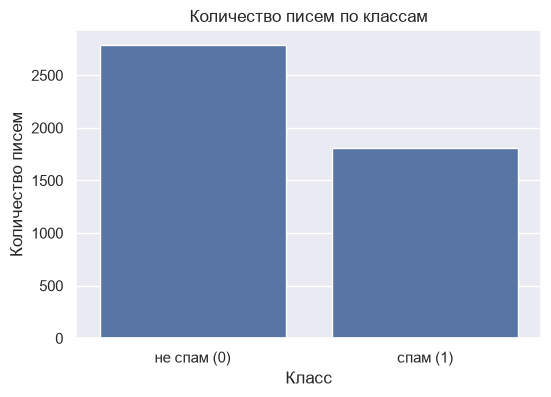

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=data['spam'], ax=ax)
ax.set_xticks([0, 1], ['не спам (0)', 'спам (1)'])
ax.set_title('Количество писем по классам')
ax.set_xlabel('Класс')
ax.set_ylabel('Количество писем')
plt.show()

Вывод: спама 39.4%, обычных писем 60.6%. Небольшой дисбаланс есть, но он не сильный, обоих классов много. Специально балансировать классы не нужно, достаточно при разбиении на train и test использовать stratify, чтобы доля спама везде была одинаковая.

В реальной почте доля спама может быть другой, так что порог все равно придется подбирать на своих данных.

Проверим, что получит модель, которая все письма считает нормальными:

In [11]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(data[features], data['spam'])
pred = dummy.predict(data[features])

print('Accuracy:', round(accuracy_score(data['spam'], pred), 3))
print('Precision:', precision_score(data['spam'], pred, zero_division=0))
print('Recall:', recall_score(data['spam'], pred))
print('F0.5:', fbeta_score(data['spam'], pred, beta=0.5, zero_division=0))

Accuracy: 0.606
Precision: 0.0
Recall: 0.0
F0.5: 0.0


Вывод: такая модель не ловит вообще ничего, но accuracy у нее 0.61. F0.5 у нее 0, то есть выбранная метрика правильно показывает, что от нее нет пользы. Это будет наш baseline.

## 10. Статистическое описание признаков

In [12]:
desc = data[features].describe().T
desc['median'] = data[features].median()
desc['skew'] = data[features].skew()
desc['доля не нулей'] = (data[features] > 0).mean()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,median,skew,доля не нулей
word_freq_make,4601.0,0.105,0.305,0.0,0.000,0.000,0.000,4.540,0.000,5.676,0.229
word_freq_address,4601.0,0.213,1.291,0.0,0.000,0.000,0.000,14.280,0.000,10.087,0.195
word_freq_all,4601.0,0.281,0.504,0.0,0.000,0.000,0.420,5.100,0.000,3.009,0.410
word_freq_3d,4601.0,0.065,1.395,0.0,0.000,0.000,0.000,42.810,0.000,26.228,0.010
word_freq_our,4601.0,0.312,0.673,0.0,0.000,0.000,0.380,10.000,0.000,4.747,0.380
word_freq_over,4601.0,0.096,0.274,0.0,0.000,0.000,0.000,5.880,0.000,5.957,0.217
word_freq_remove,4601.0,0.114,0.391,0.0,0.000,0.000,0.000,7.270,0.000,6.766,0.175
word_freq_internet,4601.0,0.105,0.401,0.0,0.000,0.000,0.000,11.110,0.000,9.725,0.179
word_freq_order,4601.0,0.090,0.279,0.0,0.000,0.000,0.000,5.260,0.000,5.226,0.168
word_freq_mail,4601.0,0.239,0.645,0.0,0.000,0.000,0.160,18.180,0.000,8.488,0.283


Вывод: у большинства признаков медиана и даже 75% квантиль равны нулю, то есть слово встречается в небольшой части писем. Стандартное отклонение больше среднего в несколько раз.

Распределения сильно скошены вправо: медиана коэффициента асимметрии (skew) по признакам около 10, у некоторых больше 30. Нормального распределения нет ни у одного признака.

Масштабы очень разные: проценты от 0 до 100, а capital_run_length_total доходит до 15841. Для логистической регрессии и kNN нужно будет масштабирование.

Чаще всего встречаются общие слова и знаки: you (в 70% писем), скобка ( , your, will.

## 11. Сколько нулей в признаках

Признаков, где нулей больше 50%: 50
Признаков, где нулей больше 90%: 19


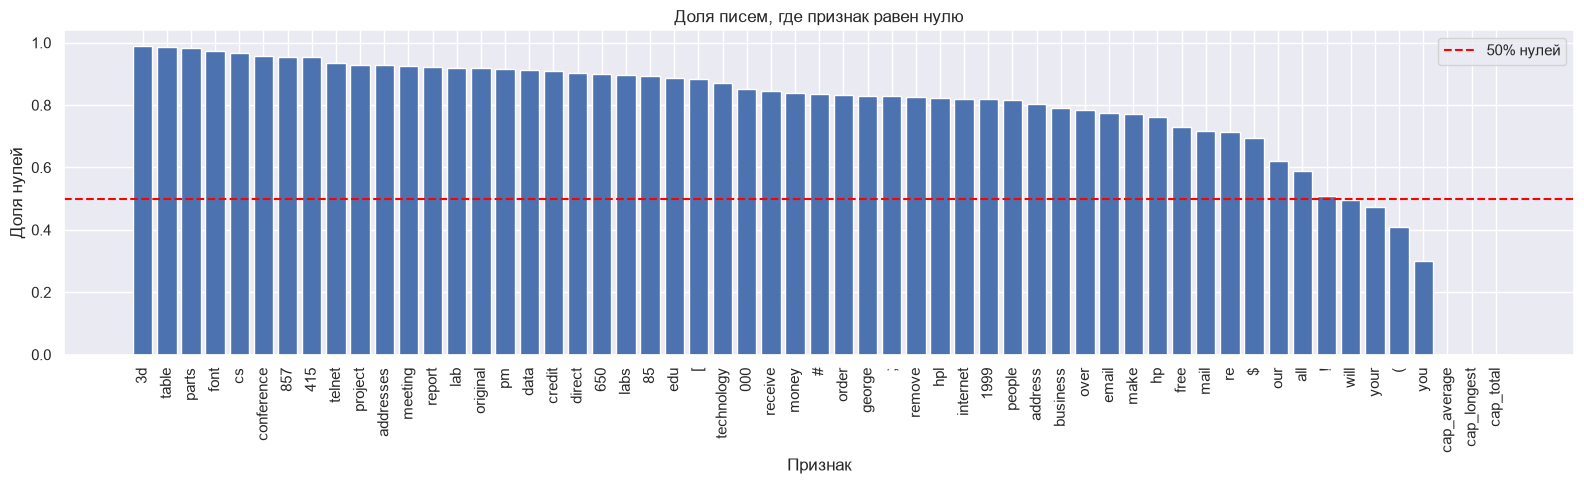

In [13]:
zeros = (data[features] == 0).mean().sort_values(ascending=False)
print('Признаков, где нулей больше 50%:', (zeros > 0.5).sum())
print('Признаков, где нулей больше 90%:', (zeros > 0.9).sum())

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(range(len(zeros)), zeros.values)
ax.axhline(0.5, color='red', linestyle='--', label='50% нулей')
ax.set_xticks(range(len(zeros)))
ax.set_xticklabels([c.replace('word_freq_', '').replace('char_freq_', '').replace('capital_run_length_', 'cap_')
                    for c in zeros.index], rotation=90)
ax.set_title('Доля писем, где признак равен нулю')
ax.set_xlabel('Признак')
ax.set_ylabel('Доля нулей')
ax.legend()
plt.tight_layout()
plt.show()

Вывод: данные очень разреженные. У 50 признаков из 57 нулей больше половины, у 19 признаков больше 90%. Слова 3d, table, parts почти не встречаются (меньше 2% писем). Не ноль всегда только у трех признаков с заглавными буквами.

Из-за этого среднее плохо описывает такие признаки, лучше смотреть на долю писем, где слово есть. Возможно, на следующих этапах стоит попробовать признаки вида "слово есть или нет". Редкие признаки пока не удаляем, они могут встречаться почти только в спаме.

## 12. Выбросы в признаках заглавных букв

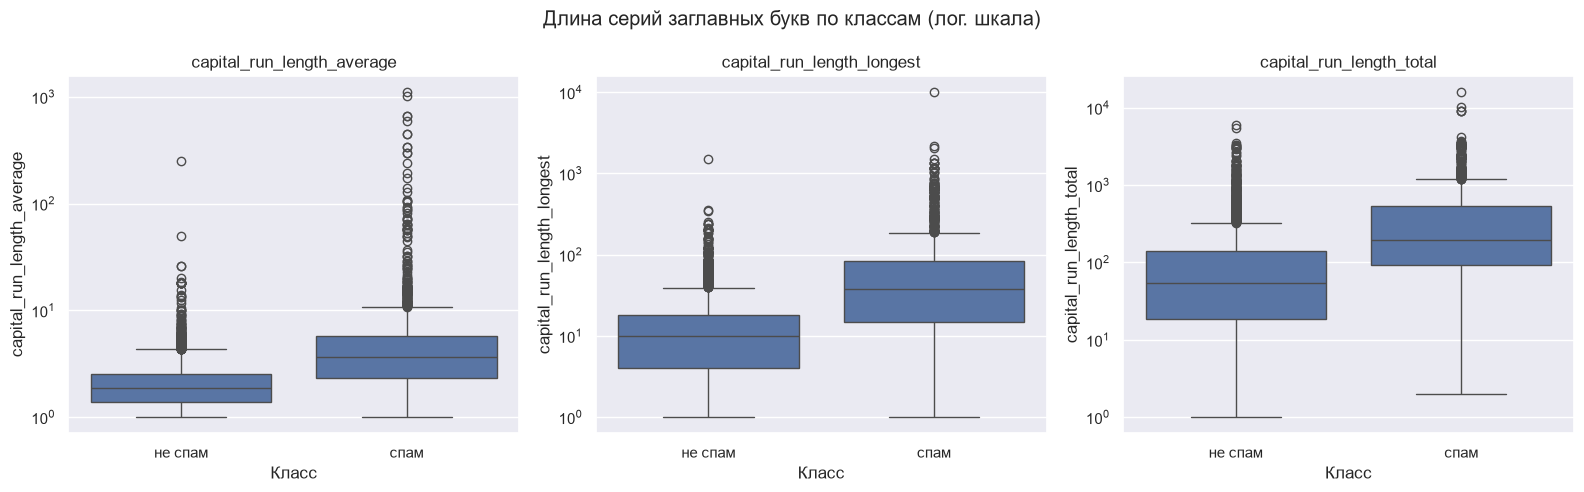

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, cap_cols):
    sns.boxplot(data=data, x='spam', y=col, ax=ax)
    ax.set_yscale('log')  # логарифмическая шкала, иначе из-за выбросов ничего не видно
    ax.set_xticks([0, 1], ['не спам', 'спам'])
    ax.set_title(col)
    ax.set_xlabel('Класс')
plt.suptitle('Длина серий заглавных букв по классам (лог. шкала)')
plt.tight_layout()
plt.show()

In [15]:
# считаем выбросы по правилу 1.5 IQR, как на лекции
for col in cap_cols:
    fliers = boxplot_stats(data[col])[0]['fliers']
    print(f'{col}: выбросов {len(fliers)} ({len(fliers) / len(data):.1%}), максимум {data[col].max()}')

capital_run_length_average: выбросов 363 (7.9%), максимум 1102.5
capital_run_length_longest: выбросов 463 (10.1%), максимум 9989
capital_run_length_total: выбросов 550 (12.0%), максимум 15841


Вывод: по правилу 1.5 IQR выбросами считаются 8-12% писем. Это не ошибки, у распределений очень длинный хвост. Например, есть письма, почти целиком написанные заглавными.

На графике видно, что у спама все три показателя заметно выше. Медиана самой длинной серии заглавных у обычных писем 10, а у спама 38. Но классы сильно пересекаются, одного этого признака мало.

Выбросы удалять не будем, большая часть из них спам, то есть это полезная информация. Чтобы они не мешали линейным моделям, лучше применить логарифм log1p.

## 13. Распределения до и после логарифмирования

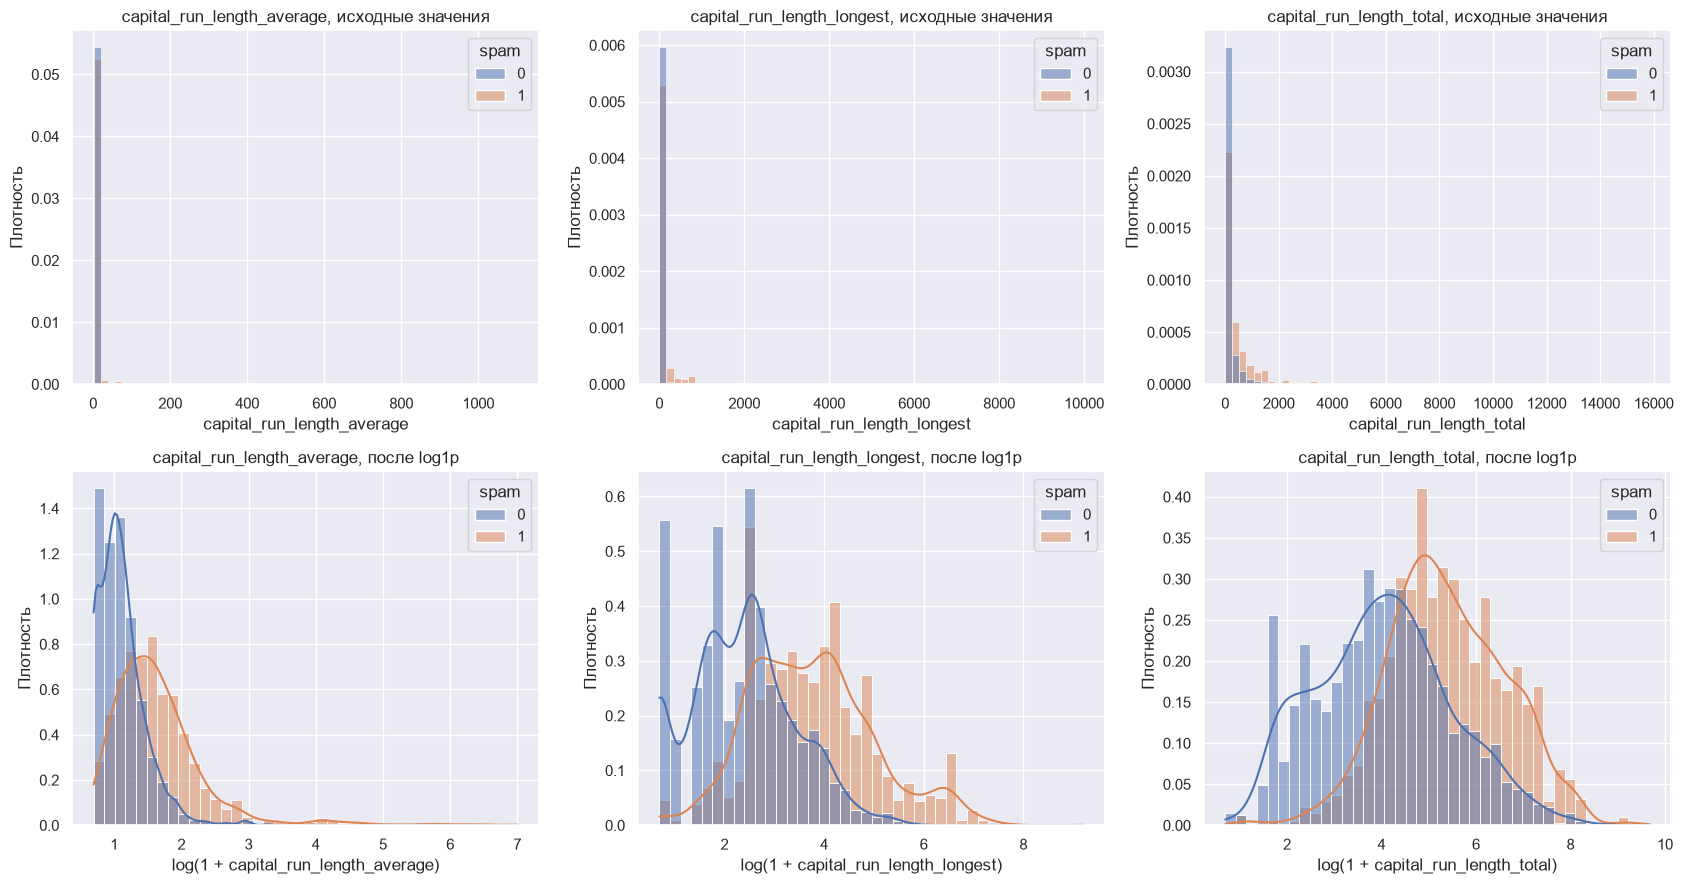

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for i, col in enumerate(cap_cols):
    sns.histplot(data=data, x=col, hue='spam', bins=60, stat='density', common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(col + ', исходные значения')
    axes[0, i].set_ylabel('Плотность')

    sns.histplot(x=np.log1p(data[col]), hue=data['spam'], bins=40, kde=True,
                 stat='density', common_norm=False, ax=axes[1, i])
    axes[1, i].set_title(col + ', после log1p')
    axes[1, i].set_xlabel('log(1 + ' + col + ')')
    axes[1, i].set_ylabel('Плотность')
plt.tight_layout()
plt.show()

Вывод: на исходных значениях почти все точки прижаты к нулю и на графике ничего не понятно. После log1p распределения становятся нормальнее, и видно, что спам (оранжевый) сдвинут вправо по всем трем признакам. Значит, перед обучением линейных моделей признаки стоит логарифмировать.

## 14. Какие слова чаще встречаются в спаме

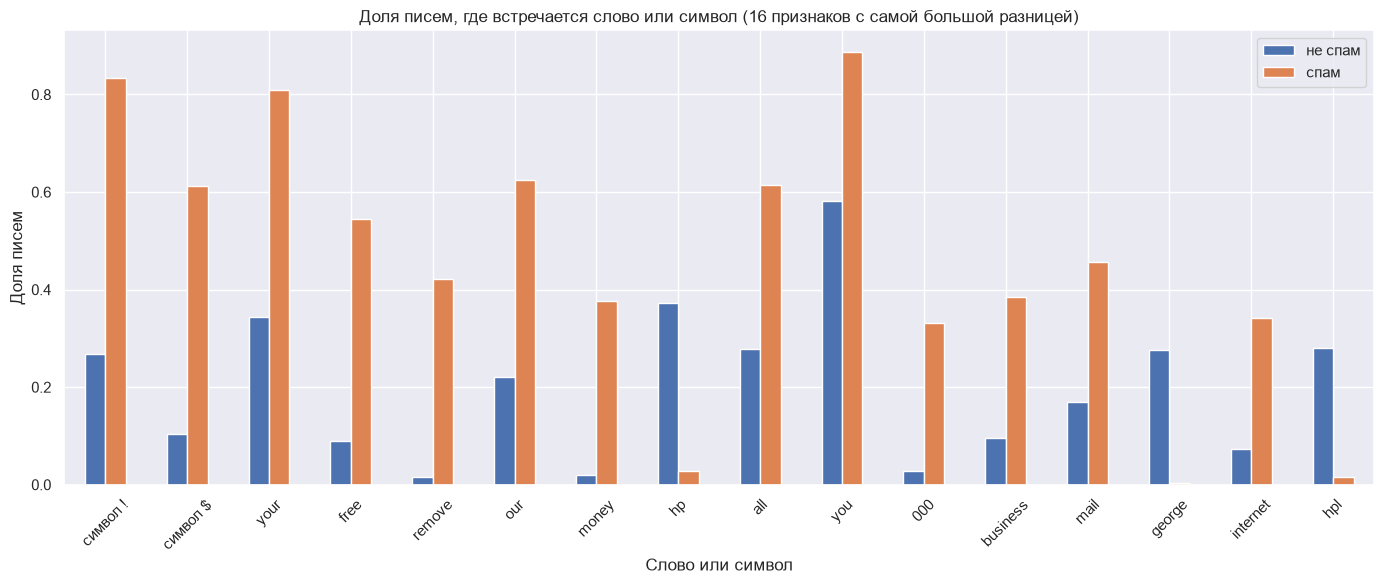

In [17]:
# доля писем, где слово встречается, отдельно для спама и не спама
share = (data[features] > 0).groupby(data['spam']).mean().T
share.columns = ['не спам', 'спам']
share['разница'] = share['спам'] - share['не спам']

top = share['разница'].abs().sort_values(ascending=False).head(16).index
plot_data = share.loc[top, ['не спам', 'спам']]
plot_data.index = [c.replace('word_freq_', '').replace('char_freq_', 'символ ') for c in top]

fig, ax = plt.subplots(figsize=(14, 6))
plot_data.plot.bar(ax=ax)
ax.set_title('Доля писем, где встречается слово или символ (16 признаков с самой большой разницей)')
ax.set_xlabel('Слово или символ')
ax.set_ylabel('Доля писем')
ax.tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()

Вывод: в спаме намного чаще встречаются символы ! и $, слова  your, free, remove, our, money, 000. Например, $ есть в 61% спама и только в 10% обычных писем. Это обычные слова для рекламы: деньги, бесплатно, отписаться (remove), суммы с нулями.

В обычных письмах чаще встречаются hp, hpl и george. Это название компании HP и имя владельца почтового ящика. То есть эти слова говорят не о спаме, а о том, откуда взяли письма. В другой компании они работать не будут.

Гипотеза на следующий этап: обучить модель с этими словами и без них. Если без них качество сильно упадет, значит оценка на этом датасете завышена.

## 15. Значения ключевых признаков, когда они не нулевые

Выше мы смотрели только на то, есть слово в письме или нет. Теперь посмотрим, отличается ли само значение признака у спама и обычных писем. Берем только письма, где признак не ноль, и логарифмируем значения.

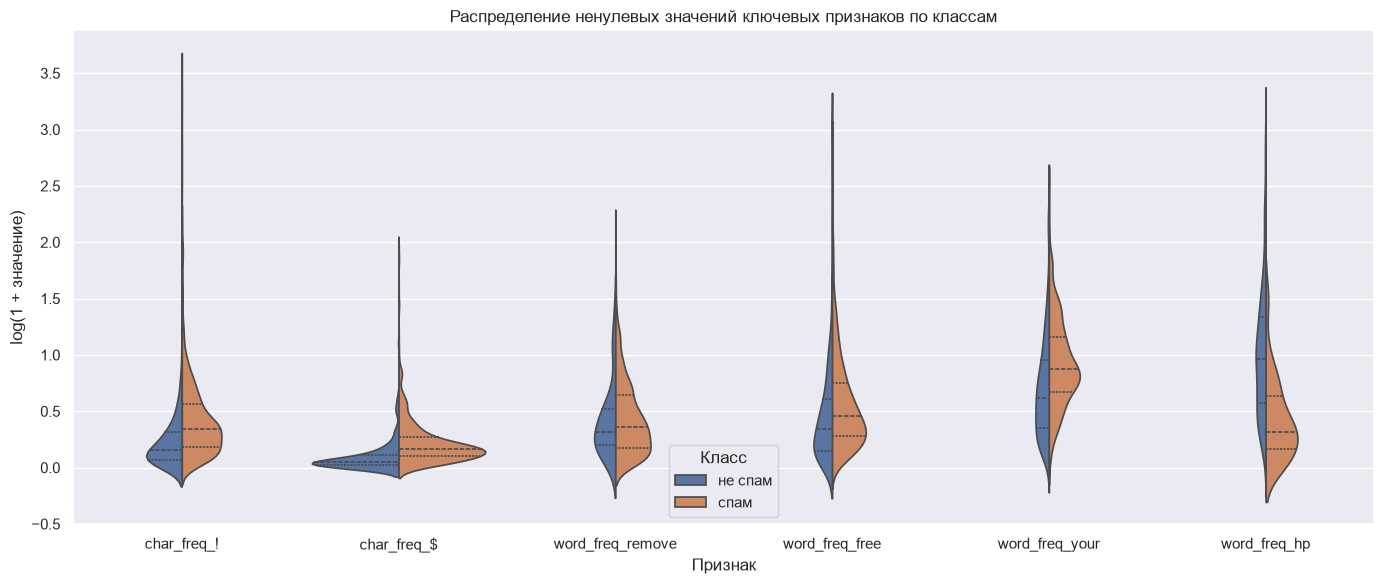

In [18]:
key = ['char_freq_!', 'char_freq_$', 'word_freq_remove', 'word_freq_free', 'word_freq_your', 'word_freq_hp']

# переводим таблицу в длинный формат: признак, значение, класс
long = data[key + ['spam']].melt(id_vars='spam', var_name='признак', value_name='значение')
long = long[long['значение'] > 0]  # оставляем только ненулевые значения
long['log_значение'] = np.log1p(long['значение'])
long['Класс'] = long['spam'].map({0: 'не спам', 1: 'спам'})

fig, ax = plt.subplots(figsize=(14, 6))
sns.violinplot(data=long, x='признак', y='log_значение', hue='Класс', hue_order=['не спам', 'спам'],
               split=True, inner='quartile', ax=ax)
ax.set_title('Распределение ненулевых значений ключевых признаков по классам')
ax.set_xlabel('Признак')
ax.set_ylabel('log(1 + значение)')
plt.tight_layout()
plt.show()

Вывод: классы отличаются не только тем, есть признак или нет, но и тем, насколько его много. Если в письме есть !, $, free или your, то у спама их доля обычно выше (оранжевая половина выше синей). У слова hp наоборот: в тех редких спам-письмах, где оно есть, его меньше, чем в обычных.

Значит, на следующих этапах полезно оставить и частоты, и признак "есть слово или нет".

## 16. Корреляции

Распределения сильно скошены, поэтому кроме корреляции Пирсона смотрим ранговую корреляцию Спирмена, она меньше реагирует на выбросы. Берем часть признаков, иначе матрица 57 на 57 не читается.

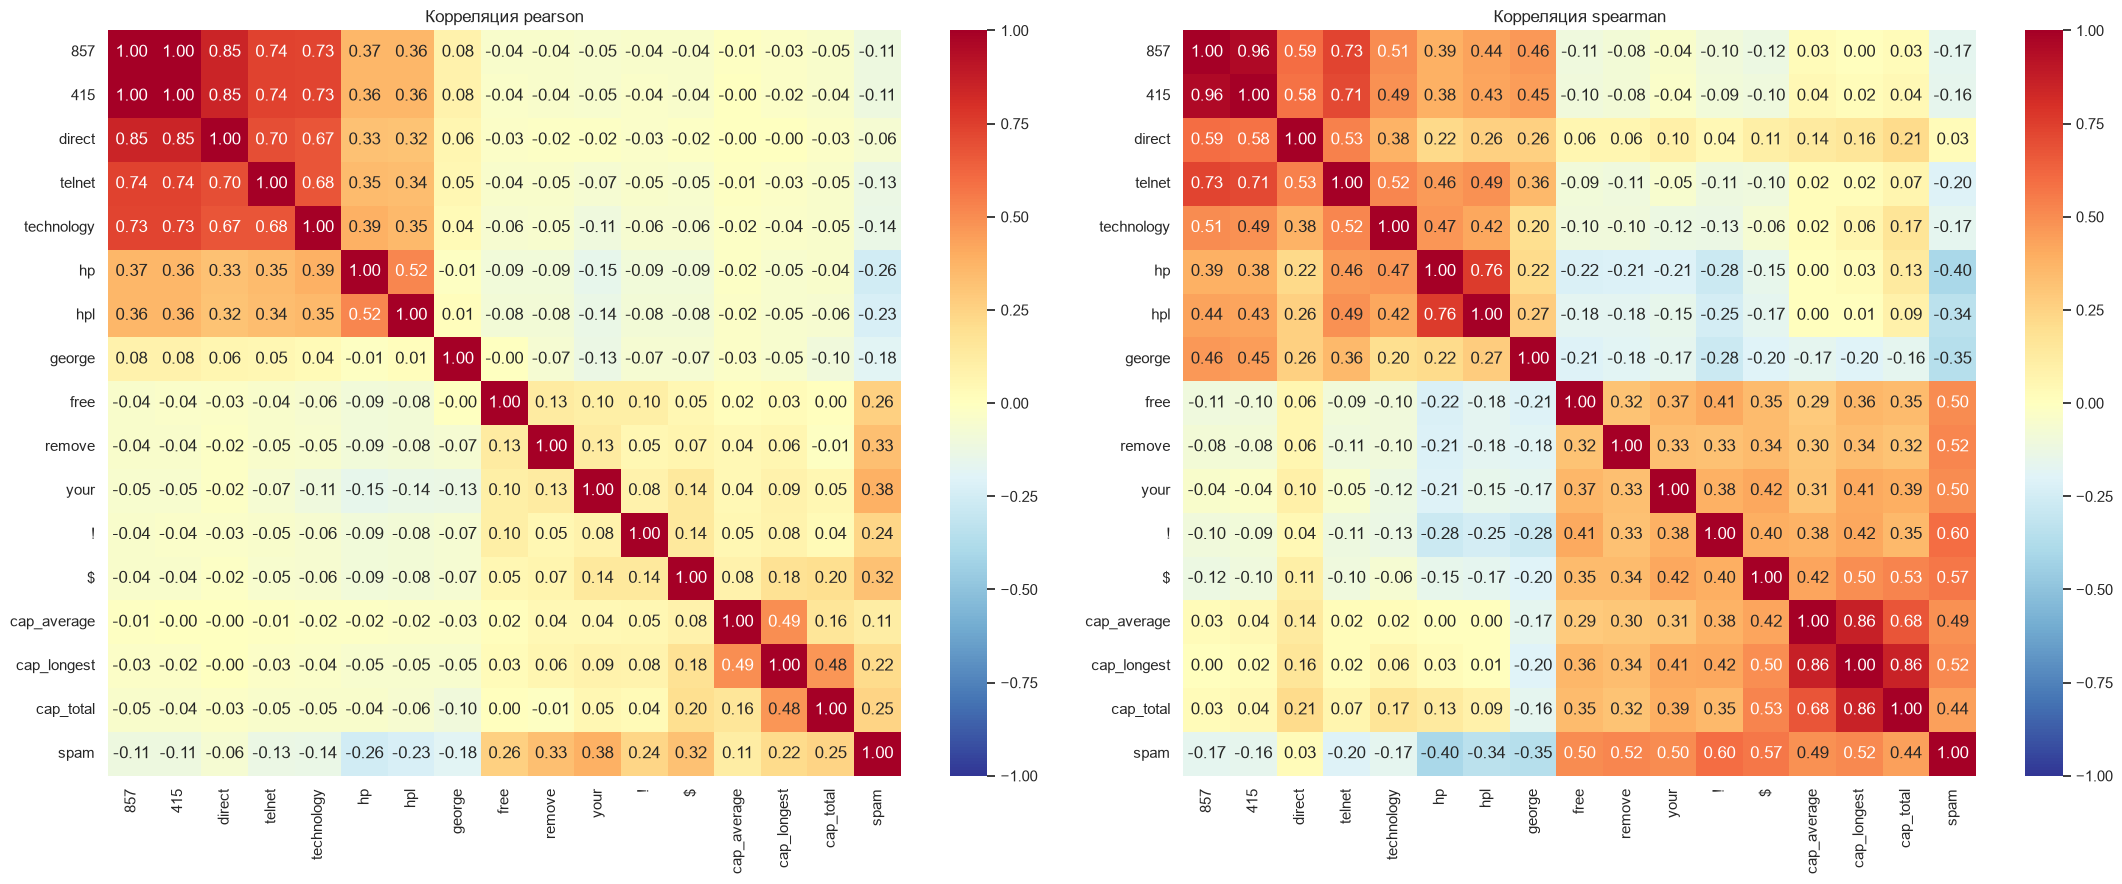

In [19]:
cols = ['word_freq_857', 'word_freq_415', 'word_freq_direct', 'word_freq_telnet', 'word_freq_technology',
        'word_freq_hp', 'word_freq_hpl', 'word_freq_george', 'word_freq_free', 'word_freq_remove',
        'word_freq_your', 'char_freq_!', 'char_freq_$'] + cap_cols + ['spam']
names = [c.replace('word_freq_', '').replace('char_freq_', '').replace('capital_run_length_', 'cap_') for c in cols]

fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, method in zip(axes, ['pearson', 'spearman']):
    corr = data[cols].corr(method=method)
    sns.heatmap(corr, cmap='RdYlBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f',
                xticklabels=names, yticklabels=names, ax=ax)
    ax.set_title('Корреляция ' + method)
plt.tight_layout()
plt.show()

In [20]:
# самые сильно связанные пары по всем признакам
corr = data[features].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
upper.stack().sort_values(ascending=False).head(6).round(3)

word_freq_857     word_freq_415           0.996
                  word_freq_direct        0.848
word_freq_415     word_freq_direct        0.845
word_freq_telnet  word_freq_857           0.738
                  word_freq_415           0.735
word_freq_857     word_freq_technology    0.730
dtype: float64

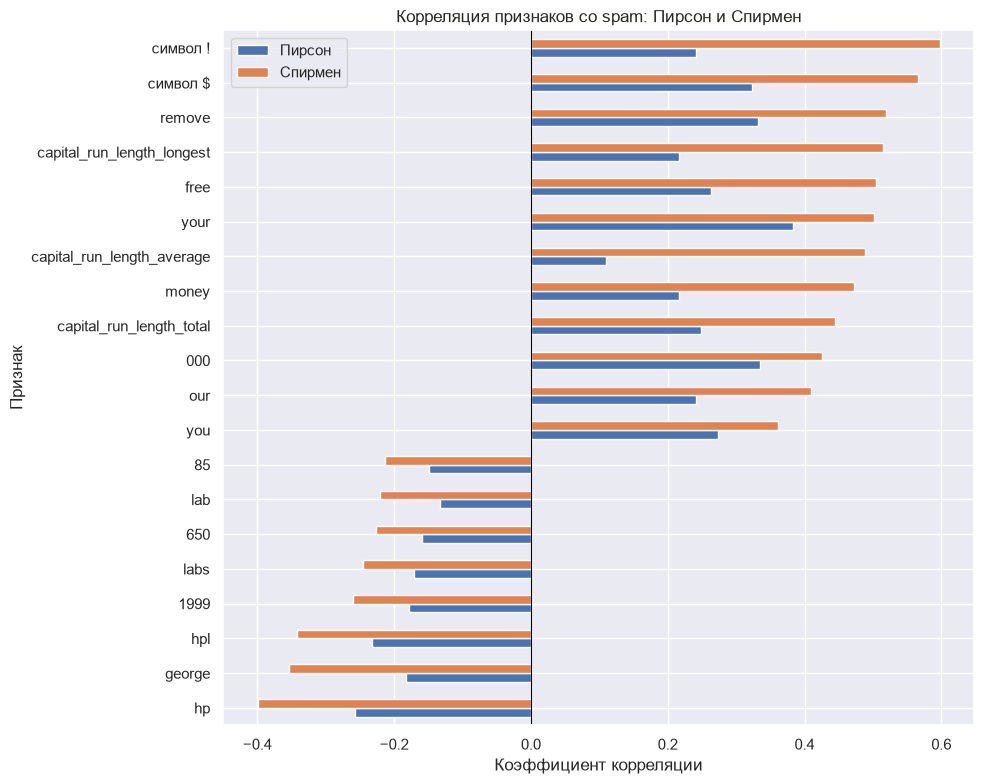

In [21]:
# связь каждого признака со spam по Пирсону и Спирмену
corr_target = pd.DataFrame({
    'Пирсон': data[features].corrwith(data['spam']),
    'Спирмен': data[features].corrwith(data['spam'], method='spearman'),
}).sort_values('Спирмен')

# 8 самых отрицательных и 12 самых положительных по Спирмену
sel = pd.concat([corr_target.head(8), corr_target.tail(12)])
sel.index = [c.replace('word_freq_', '').replace('char_freq_', 'символ ') for c in sel.index]

fig, ax = plt.subplots(figsize=(10, 8))
sel.plot.barh(ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Корреляция признаков со spam: Пирсон и Спирмен')
ax.set_xlabel('Коэффициент корреляции')
ax.set_ylabel('Признак')
plt.tight_layout()
plt.show()

Вывод: слова 857 и 415 почти полностью повторяют друг друга (корреляция 0.996), с ними сильно связаны direct, telnet, technology (0.67-0.85). Скорее всего это одна и та же подпись с номером телефона. Для линейной регрессии это мультиколлинеарность, поэтому из пары 857 и 415 лучше оставить одно или использовать регуляризацию. Три признака заглавных букв тоже сильно связаны между собой по Спирмену (0.68-0.86).

Если смотреть на связь со spam, Спирмен показывает намного более сильную связь, чем Пирсон. Например, для ! Пирсон 0.24, а Спирмен 0.60, для длинной серии заглавных 0.22 против 0.52. Это из-за выбросов и большого количества нулей. Значит, на одну корреляцию Пирсона в этих данных полагаться нельзя.

Знак ! не делает письмо спамом, он просто чаще встречается в спаме.

## 17. Совместное распределение ключевых признаков

Рассмотрим четыре самых сильных признака вместе, чтобы понять, разделяются ли классы, если смотреть на несколько признаков сразу. Для читаемости берем случайные 1500 писем (random_state=42), значения логарифмируем.

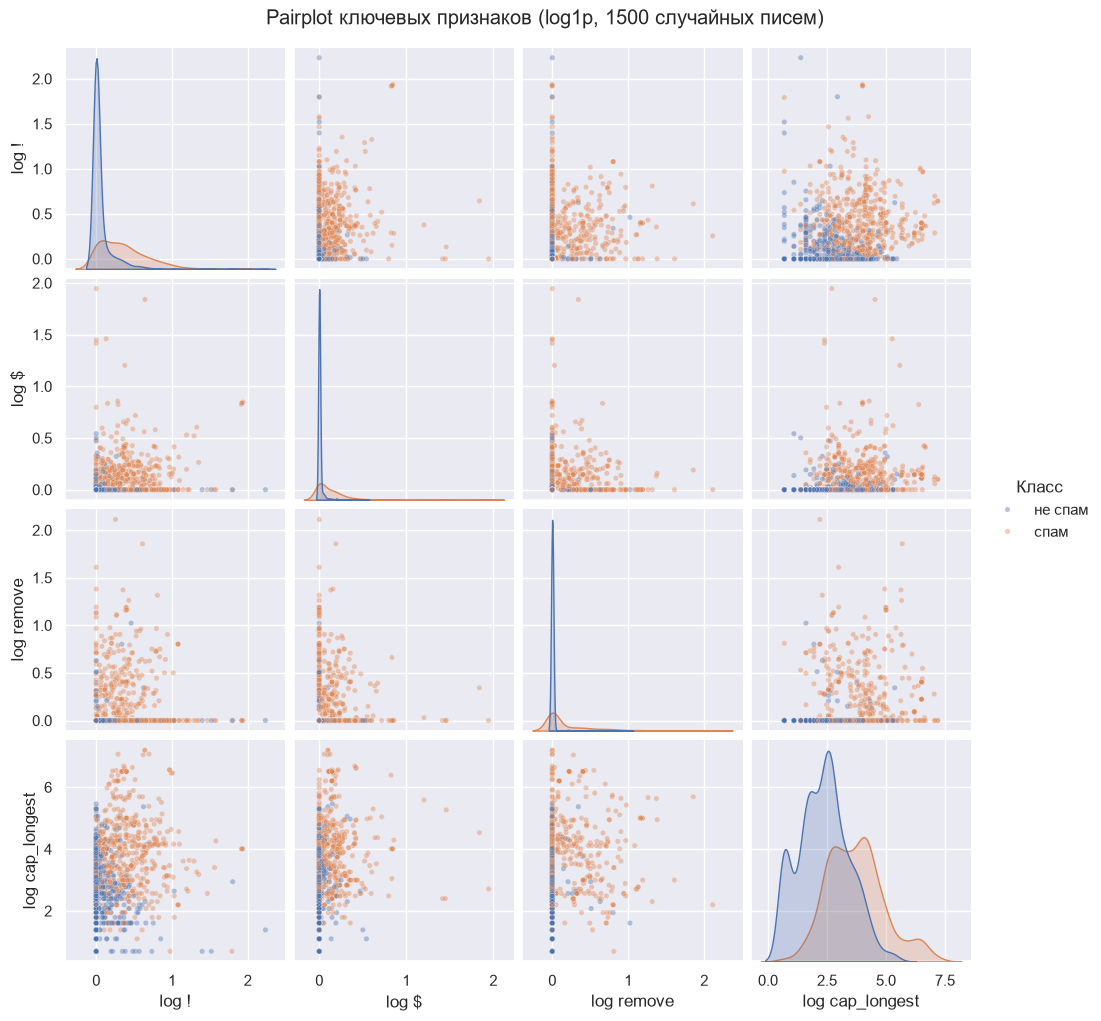

In [22]:
pair_cols = ['char_freq_!', 'char_freq_$', 'word_freq_remove', 'capital_run_length_longest']
pair_df = np.log1p(data[pair_cols])
pair_df.columns = ['log !', 'log $', 'log remove', 'log cap_longest']
pair_df['Класс'] = data['spam'].map({0: 'не спам', 1: 'спам'})

g = sns.pairplot(pair_df.sample(1500, random_state=42), hue='Класс', hue_order=['не спам', 'спам'],
                 plot_kws={'alpha': 0.4, 's': 15})
g.figure.suptitle('Pairplot ключевых признаков (log1p, 1500 случайных писем)', y=1.02)
plt.show()

Вывод: много писем лежит прямо на осях, то есть у них какой-то из признаков равен нулю, и там спам с обычными письмами перемешан. Там, где признаки не нулевые, спам занимает правую верхнюю часть: письмо, где одновременно есть ! и $ и длинные серии заглавных, почти всегда спам.

Граница между классами есть, но по одному признаку ее не провести, нужна комбинация нескольких. Это говорит в пользу многомерной модели, например логистической регрессии, а потом деревьев.

## 18. PCA

Посмотрим, разделяются ли классы, если сжать все 57 признаков до двух. Перед PCA делаем log1p и StandardScaler, иначе компоненты будут описывать только выбросы.

Доля объясненной дисперсии: [0.134 0.09 ]


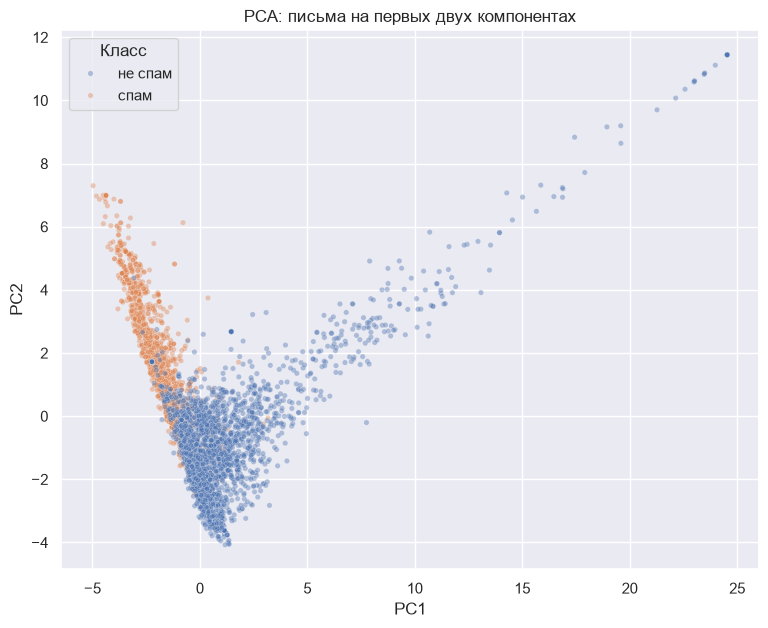

In [23]:
X = StandardScaler().fit_transform(np.log1p(data[features]))
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
print('Доля объясненной дисперсии:', pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=data['spam'].map({0: 'не спам', 1: 'спам'}),
                hue_order=['не спам', 'спам'], alpha=0.4, s=15, ax=ax)
ax.set_title('PCA: письма на первых двух компонентах')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(title='Класс')
plt.show()

Вывод: две компоненты объясняют всего 22% дисперсии, это мало, но так и должно быть при 57 разреженных признаках. Тем не менее классы частично разделяются: спам (оранжевый) уходит влево вверх, обычные письма вправо и вниз, в середине они перемешаны. Задача решаемая, но идеального разделения ждать не стоит (в описании датасета ошибка около 7%).

## 19. Итоговые выводы

1. В датасете 4601 письмо и 57 числовых признаков, спама 39.4%. Данные совпадают с описанием на UCI. Текстов писем нет, только посчитанные признаки.

2. Пропусков и некорректных значений нет. Есть 391 дубликат и 3 группы с разной меткой. Данные старые и из одной компании, часть слов (george, hp, hpl, 650, 857, 415) связана с этой компанией, а не со спамом.

3. Признаки очень разреженные и сильно скошенные, есть большие выбросы в признаках заглавных букв.

4. Спам лучше всего выделяют ! и $, слова remove, free, your, money, 000 и длинные серии заглавных букв.

5. Признаки 857 и 415 почти дублируют друг друга.

6. Корреляция Пирсона здесь занижает связь, лучше смотреть Спирмена.

Перед обучением модели:
* удалить дубликаты до разбиения на train и test;
* разбивать со stratify по spam;
* применить log1p ко всем признакам;
* для логистической регрессии и kNN сделать StandardScaler (обучать только на train);
* убрать один из признаков 857 или 415 или использовать регуляризацию;
* выбросы не удалять.

Cледующие этапы:
* логистическая регрессия на логарифмированных признаках будет намного лучше baseline (F0.5 = 0);
* признаки "слово есть или нет" будут работать не хуже частот;
* без слов george, hp и других "локальных" слов качество упадет;
* подбор порога по кривой Precision-Recall позволит поднять Precision.